# Log-Normal Distribution

Companion notebook for the [log-normal note](../../notes/random_variables_and_distributions/continuous/log_normal_distribution.md) and its [exercises](../../exercises/random_variables_and_distributions/log_normal_distribution.md).

$X=e^Y$ with $Y\sim N(\mu,\sigma^2)$:

$$f(x)=\frac1{x\sigma\sqrt{2\pi}}\exp\!\left(-\frac{(\ln x-\mu)^2}{2\sigma^2}\right),\quad E[X]=e^{\mu+\sigma^2/2},\quad \operatorname{Var}(X)=(e^{\sigma^2}-1)e^{2\mu+\sigma^2}.$$

In scipy, `lognorm(s=sigma, scale=exp(mu))`.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

rng = np.random.default_rng(42)  # seeded for reproducible simulations
from scipy.special import erf

## Hand-rolled implementation

The CDF is the normal CDF of $\ln x$: $F(x)=\tfrac12\left[1+\operatorname{erf}\!\left(\frac{\ln x-\mu}{\sigma\sqrt2}\right)\right]$.

In [2]:
class LogNormalDistribution:
    """X = exp(Y) with Y ~ N(mu, sigma^2)."""

    def __init__(self, mu, sigma):
        self.mu = mu
        self.sigma = sigma

    def pdf(self, x):
        x = np.asarray(x, dtype=float)
        prefactor = 1 / (x * self.sigma * np.sqrt(2 * np.pi))
        return prefactor * np.exp(-((np.log(x) - self.mu) ** 2) / (2 * self.sigma**2))

    def cdf(self, x):
        x = np.asarray(x, dtype=float)
        return 0.5 * (1 + erf((np.log(x) - self.mu) / (self.sigma * np.sqrt(2))))

    def mean(self):
        return np.exp(self.mu + self.sigma**2 / 2)

    def var(self):
        return (np.exp(self.sigma**2) - 1) * np.exp(2 * self.mu + self.sigma**2)

## Check against `scipy.stats`

In [3]:
mu1, s1 = 0.0, 0.5
mu2, s2 = 0.0, 1.0
x = np.linspace(0.01, 5, 1000)
d1, d2 = LogNormalDistribution(mu1, s1), LogNormalDistribution(mu2, s2)

pdf1, pdf2 = stats.lognorm.pdf(x, s1, scale=np.exp(mu1)), stats.lognorm.pdf(x, s2, scale=np.exp(mu2))
cdf1, cdf2 = stats.lognorm.cdf(x, s1, scale=np.exp(mu1)), stats.lognorm.cdf(x, s2, scale=np.exp(mu2))
print("PDF matches:", np.allclose(d1.pdf(x), pdf1), np.allclose(d2.pdf(x), pdf2))
print("CDF matches:", np.allclose(d1.cdf(x), cdf1), np.allclose(d2.cdf(x), cdf2))
print("mean/var match:", np.isclose(d1.mean(), stats.lognorm.mean(s1)), np.isclose(d1.var(), stats.lognorm.var(s1)))

PDF matches: True True
CDF matches: True True
mean/var match: True True


## Shape of the PDF and CDF

Larger $\sigma$ makes the distribution more right-skewed: the mode moves toward 0 while the mean ($e^{\sigma^2/2}$ when $\mu=0$) increases.

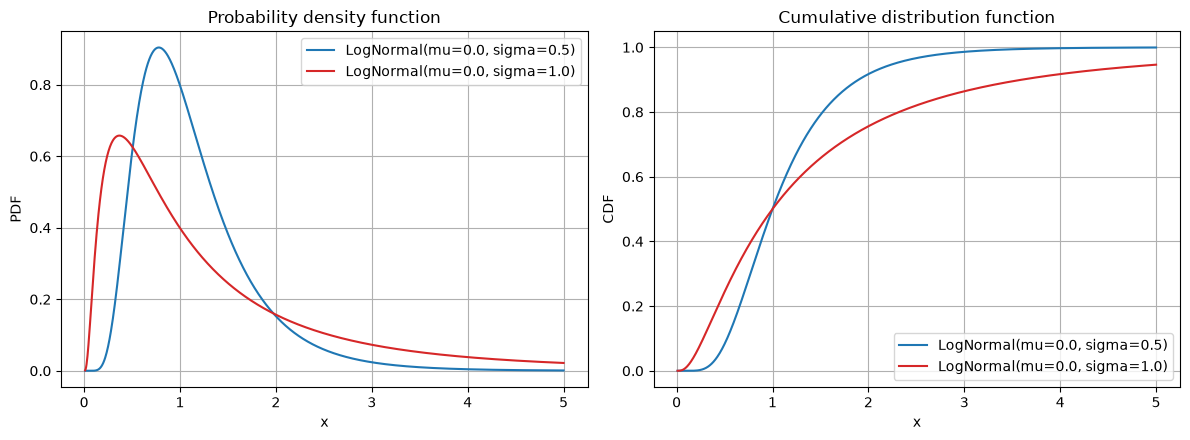

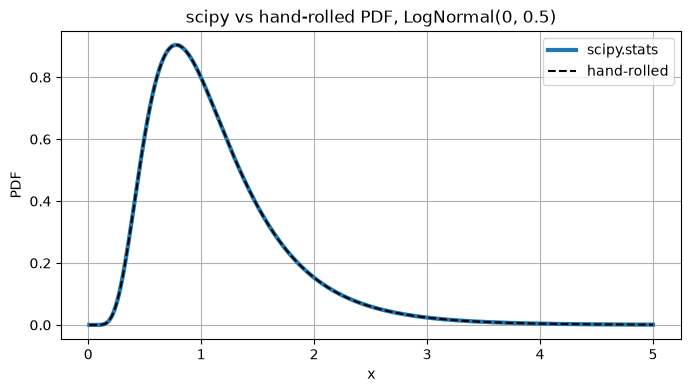

In [4]:
def plot_pdf_cdf(x, pdf1, cdf1, label1, pdf2, cdf2, label2):
    """PDF and CDF of two distributions side by side."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
    ax1.plot(x, pdf1, color="C0", label=label1)
    ax1.plot(x, pdf2, color="C3", label=label2)
    ax1.set(xlabel="x", ylabel="PDF", title="Probability density function")
    ax2.plot(x, cdf1, color="C0", label=label1)
    ax2.plot(x, cdf2, color="C3", label=label2)
    ax2.set(xlabel="x", ylabel="CDF", title="Cumulative distribution function")
    for ax in (ax1, ax2):
        ax.legend()
        ax.grid(True)
    plt.tight_layout()
    plt.show()


def plot_overlay(x, ref, custom, title):
    """Hand-rolled PDF (dashed) on top of the scipy.stats PDF (solid)."""
    plt.figure(figsize=(8, 4))
    plt.plot(x, ref, color="C0", linewidth=3, label="scipy.stats")
    plt.plot(x, custom, "k--", label="hand-rolled")
    plt.xlabel("x")
    plt.ylabel("PDF")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()


plot_pdf_cdf(x, pdf1, cdf1, f"LogNormal(mu={mu1}, sigma={s1})", pdf2, cdf2, f"LogNormal(mu={mu2}, sigma={s2})")
plot_overlay(x, pdf1, d1.pdf(x), "scipy vs hand-rolled PDF, LogNormal(0, 0.5)")

## Worked example: stock price and the mean-median-mode ordering

From the note: $\mu=0$, $\sigma=0.1$ gives mean $\approx1.005$ and variance $\approx0.0102$. For a skewed case ($\mu=2$, $\sigma=0.5$) we have mode $<$ median $<$ mean.

In [5]:
stock = LogNormalDistribution(0.0, 0.1)
print(f"E[X] = {stock.mean():.5f}, Var(X) = {stock.var():.5f}")

skew = LogNormalDistribution(2.0, 0.5)
mode, median, mean = math.exp(2 - 0.25), math.exp(2), skew.mean()
print(f"mode {mode:.3f} < median {median:.3f} < mean {mean:.3f}")

# Moment matching: positive variable with mean 10 and variance 20
sigma2 = math.log(1 + 20 / 10**2)
mu = math.log(10) - sigma2 / 2
print(f"mean 10, var 20  ->  mu = {mu:.4f}, sigma = {math.sqrt(sigma2):.4f}")

E[X] = 1.00501, Var(X) = 0.01015
mode 5.755 < median 7.389 < mean 8.373
mean 10, var 20  ->  mu = 2.2114, sigma = 0.4270


## Simulation versus theory

Exponentiating normal draws gives log-normal draws; a log-transformed sample should look normal.

mean: sample 1.6517  theory 1.6487
var : sample 5.0732  theory 4.6708  (heavy tail: slow convergence)
median: sample 0.9910  theory 1.0000
mean of ln(sample): -0.0042 (mu = 0.0),  sd: 1.0037 (sigma = 1.0)


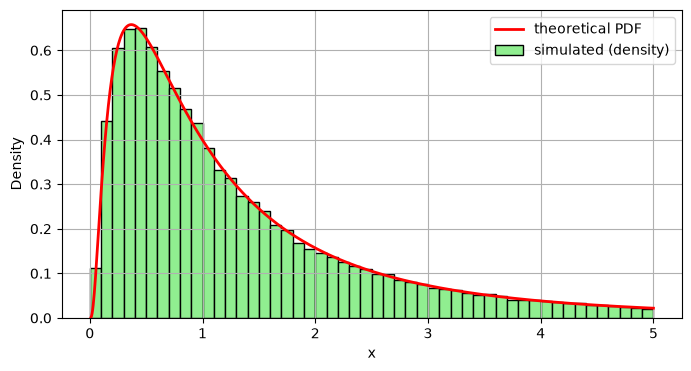

In [6]:
sample = np.exp(rng.normal(mu2, s2, size=100_000))
print(f"mean: sample {sample.mean():.4f}  theory {d2.mean():.4f}")
print(f"var : sample {sample.var():.4f}  theory {d2.var():.4f}  (heavy tail: slow convergence)")
print(f"median: sample {np.median(sample):.4f}  theory {math.exp(mu2):.4f}")
print(f"mean of ln(sample): {np.log(sample).mean():.4f} (mu = {mu2}),  sd: {np.log(sample).std():.4f} (sigma = {s2})")

# Histogram of the bulk of the distribution (values above 5 are not shown)
width = 0.1
edges = np.arange(0, 5 + width, width)
counts, _ = np.histogram(sample, bins=edges)
plt.figure(figsize=(8, 4))
plt.bar(edges[:-1], counts / (sample.size * width), width=width, align="edge",
        color="lightgreen", edgecolor="black", label="simulated (density)")
plt.plot(x, pdf2, "r-", linewidth=2, label="theoretical PDF")
plt.xlabel("x")
plt.ylabel("Density")
plt.legend()
plt.grid(True)
plt.show()

## Takeaways

* $\ln X$ is normal, so log-normal quantities arise from products of many small positive effects.
* The mean exceeds the median $e^\mu$, which exceeds the mode $e^{\mu-\sigma^2}$.
* The sample variance of heavy-tailed log-normals converges slowly; large $\sigma$ needs large samples.